# SCIN Exploratory Data Analysis

In [1]:
#Preprocessor Directives
from datasets import load_dataset
from huggingface_hub import login
import pandas as pd
import numpy as np
from pathlib import Path
import io
import random
from PIL import Image as PILImage
from datasets import Image
import pyarrow.compute as pc
import matplotlib.pyplot as plt
from collections import Counter
from ast import literal_eval


/Users/omarjibreen/College/Fall 2026/ProGSU/Hacklanta/PaliDerm/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', None)


## Load Dataset

In [3]:
dataset = load_dataset("google/scin", split="train")

Some datasets params were ignored: ['splits', 'download_size', 'dataset_size']. Make sure to use only valid params for the dataset builder and to have a up-to-date version of the `datasets` library.


In [4]:
print(dataset)
print(dataset.cache_files)

Dataset({
    features: ['case_id', 'source', 'release', 'year', 'age_group', 'sex_at_birth', 'fitzpatrick_skin_type', 'race_ethnicity_american_indian_or_alaska_native', 'race_ethnicity_asian', 'race_ethnicity_black_or_african_american', 'race_ethnicity_hispanic_latino_or_spanish_origin', 'race_ethnicity_middle_eastern_or_north_african', 'race_ethnicity_native_hawaiian_or_pacific_islander', 'race_ethnicity_white', 'race_ethnicity_other_race', 'race_ethnicity_prefer_not_to_answer', 'textures_raised_or_bumpy', 'textures_flat', 'textures_rough_or_flaky', 'textures_fluid_filled', 'body_parts_head_or_neck', 'body_parts_arm', 'body_parts_palm', 'body_parts_back_of_hand', 'body_parts_torso_front', 'body_parts_torso_back', 'body_parts_genitalia_or_groin', 'body_parts_buttocks', 'body_parts_leg', 'body_parts_foot_top_or_side', 'body_parts_foot_sole', 'body_parts_other', 'condition_symptoms_bothersome_appearance', 'condition_symptoms_bleeding', 'condition_symptoms_increasing_size', 'condition_sy

In [5]:
files = [Path(f["filename"]) for f in dataset.cache_files]

print("Cases:", len(dataset))
print("Arrow shards:", len(files))
print("Missing shards:", sum(not p.is_file() for p in files))
print("Empty shards:", sum(p.stat().st_size == 0 for p in files if p.exists()))
print("Total GB:", round(sum(p.stat().st_size for p in files) / 1024**3, 2))

Cases: 5033
Arrow shards: 19
Missing shards: 0
Empty shards: 0
Total GB: 11.74


In [6]:
raw = dataset

for col in ["image_1_path", "image_2_path", "image_3_path"]:
    if isinstance(raw.features[col], Image):
        raw = raw.cast_column(col, Image(decode=False))

for col in ["image_1_path", "image_2_path", "image_3_path"]:
    value = raw[0][col]

    if isinstance(value, dict):
        data = value.get("bytes")
        print(col, {
            "embedded_bytes": len(data) if data else 0,
            "external_path": value.get("path")
        })
    else:
        print(col, str(value)[:200])

image_1_path {'embedded_bytes': 999902, 'external_path': '-3205742176803893704.png'}
image_2_path None
image_3_path None


In [7]:
rng = random.Random(42)
indices = rng.sample(range(len(raw)), min(30, len(raw)))

checked = 0
failed = []

for i in indices:
    case = raw[i]

    for col in ["image_1_path", "image_2_path", "image_3_path"]:
        item = case[col]

        if item is None:
            continue

        try:
            if isinstance(item, dict) and item.get("bytes"):
                with PILImage.open(io.BytesIO(item["bytes"])) as img:
                    img.verify()
                checked += 1
            else:
                failed.append((i, col, "No embedded image bytes"))
        except Exception as e:
            failed.append((i, col, str(e)))

print("Images verified:", checked)
print("Failures:", failed[:10])

Images verified: 65
Failures: []


## EDA

In [8]:
#Metadata only
image_cols = [
    "image_1_path",
    "image_2_path",
    "image_3_path"
]

# Start with lightweight metadata
df = dataset.remove_columns(image_cols).to_pandas()

# Add filenames without copying image bytes
table = raw.data.table

df = table.drop(image_cols).append_column(
    "image_1_path", pc.struct_field(table["image_1_path"], "path")
).append_column(
    "image_2_path", pc.struct_field(table["image_2_path"], "path")
).append_column(
    "image_3_path", pc.struct_field(table["image_3_path"], "path")
).to_pandas()

display(df.head())

,case_id,source,release,year,age_group,sex_at_birth,fitzpatrick_skin_type,race_ethnicity_american_indian_or_alaska_native,race_ethnicity_asian,race_ethnicity_black_or_african_american,race_ethnicity_hispanic_latino_or_spanish_origin,race_ethnicity_middle_eastern_or_north_african,race_ethnicity_native_hawaiian_or_pacific_islander,race_ethnicity_white,race_ethnicity_other_race,race_ethnicity_prefer_not_to_answer,textures_raised_or_bumpy,textures_flat,textures_rough_or_flaky,textures_fluid_filled,body_parts_head_or_neck,body_parts_arm,body_parts_palm,body_parts_back_of_hand,body_parts_torso_front,body_parts_torso_back,body_parts_genitalia_or_groin,body_parts_buttocks,body_parts_leg,body_parts_foot_top_or_side,body_parts_foot_sole,body_parts_other,condition_symptoms_bothersome_appearance,condition_symptoms_bleeding,condition_symptoms_increasing_size,condition_symptoms_darkening,condition_symptoms_itching,condition_symptoms_burning,condition_symptoms_pain,condition_symptoms_no_relevant_experience,other_symptoms_fever,other_symptoms_chills,other_symptoms_fatigue,other_symptoms_joint_pain,other_symptoms_mouth_sores,other_symptoms_shortness_of_breath,other_symptoms_no_relevant_symptoms,related_category,condition_duration,image_1_shot_type,image_2_shot_type,image_3_shot_type,combined_race,race_ethnicity_two_or_more_after_mitigation,dermatologist_gradable_for_skin_condition_1,dermatologist_gradable_for_skin_condition_2,dermatologist_gradable_for_skin_condition_3,dermatologist_skin_condition_on_label_name,dermatologist_skin_condition_confidence,weighted_skin_condition_label,dermatologist_gradable_for_fitzpatrick_skin_type_1,dermatologist_gradable_for_fitzpatrick_skin_type_2,dermatologist_gradable_for_fitzpatrick_skin_type_3,dermatologist_fitzpatrick_skin_type_label_1,dermatologist_fitzpatrick_skin_type_label_2,dermatologist_fitzpatrick_skin_type_label_3,gradable_for_monk_skin_tone_india,gradable_for_monk_skin_tone_us,monk_skin_tone_label_india,monk_skin_tone_label_us,image_1_path,image_2_path,image_3_path
0,-1000600354148496558,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YES,NaN,NaN,NaN,YES,YES,NaN,YES,YES,YES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YES,RASH,ONE_DAY,CLOSE_UP,NaN,NaN,NaN,NaN,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Inflicted skin lesions', 'Eczema', 'Irritant...","[4, 4, 3]","{'Inflicted skin lesions': 0.41, 'Eczema': 0.4...",YES,NaN,NaN,FST2,NaN,NaN,True,True,2.0,1.0,-3205742176803893704.png,NaN,NaN
1,-1002039107727665188,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CLOSE_UP,NaN,NaN,NaN,NaN,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Prurigo nodularis', 'Actinic Keratosis', 'SC...","[4, 3, 4]","{'Prurigo nodularis': 0.41, 'SCC/SCCIS': 0.41,...",YES,NaN,NaN,FST1,NaN,NaN,True,True,3.0,3.0,-4762289084741430925.png,NaN,NaN
2,-1003358831658393077,SCIN,1.0.0,2023,AGE_18_TO_29,MALE,NONE_IDENTIFIED,NaN,NaN,NaN,YES,NaN,NaN,NaN,NaN,NaN,NaN,YES,YES,NaN,NaN,YES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YES,NaN,YES,YES,YES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YES,OTHER_ISSUE_DESCRIPTION,ONE_TO_FOUR_WEEKS,CLOSE_UP,NaN,NaN,HISPANIC_LATINO_OR_SPANISH_ORIGIN,NaN,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Impetigo', 'Herpes Zoster', 'Bullous dermati...","[2, 1, 1]","{'Impetigo': 0.55, 'Herpes Zoster': 0.23, 'Bul...",YES,NaN,NaN,FST4,NaN,NaN,True,True,3.0,4.0,-4027806997035329030.png,NaN,NaN
3,-1003826561155964328,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YES,NaN,YES,NaN,NaN,NaN,YES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YES,YES,YES,NaN,NaN,NaN,NaN,NaN,NaN,NaN,YES,OTHER_ISSUE_DESCRIPTION,ONE_DAY,AT_DISTANCE,AT_AN_ANGLE,CLOSE_UP,NaN,NaN,NO_IMAGE_QUALITY_INSUFFICIENT,NaN,NaN,[],[],{},NO,NaN,NaN,NaN,NaN,NaN,True,Tr

### Removing Derived Data

In [9]:
df.drop(columns=['combined_race', 'race_ethnicity_two_or_more_after_mitigation'], inplace=True)

### Encoding and Null handling

In [10]:
#Unique Values in each column with nan values
nan_cols = df.columns[df.isna().any()]
unique_table = pd.DataFrame({
    'Column Name': nan_cols,
    'Unique Values': [df[col].unique().tolist() for col in nan_cols]
})
display(unique_table)

,Column Name,Unique Values
0,age_group,"[AGE_UNKNOWN, AGE_18_TO_29, AGE_40_TO_49, AGE_..."
1,sex_at_birth,"[OTHER_OR_UNSPECIFIED, MALE, FEMALE, nan]"
2,fitzpatrick_skin_type,"[nan, NONE_IDENTIFIED, FST3, FST1, FST4, FST2,..."
3,race_ethnicity_american_indian_or_alaska_native,"[nan, YES]"
4,race_ethnicity_asian,"[nan, YES]"
5,race_ethnicity_black_or_african_american,"[nan, YES]"
6,race_ethnicity_hispanic_latino_or_spanish_origin,"[nan, YES]"
7,race_ethnicity_middle_eastern_or_north_african,"[nan, YES]"
8,race_ethnicity_native_hawaiian_or_pacific_isla...,"[nan, YES]"
9,race_ethnicity_white,"[nan, YES]"


In [11]:
#Encoding binary columns
bin_prefixes = ("race_ethnicity_",
                "textures_",
                "body_parts_",
                "condition_symptoms_",
                "other_symptoms_")
bin_cols = binary_cols = df.columns[df.columns.str.startswith((bin_prefixes))]
for col in binary_cols:
    if df[col].eq("YES").any():
        df[col] = df[col].eq("YES").astype("uint8")

gradable_cols = df.columns[
    df.columns.str.contains("gradable_for_")
]

df[gradable_cols] = df[gradable_cols].replace({
    "YES": np.uint8(1),
    True: np.uint8(1),
    "NO": np.uint8(0),
    False: np.uint8(0)})

In [12]:
#Encoding Missing Data
fill_values = {
    "age_group": "AGE_UNKNOWN",
    "sex_at_birth": "OTHER_OR_UNSPECIFIED",
    "fitzpatrick_skin_type": "UNKNOWN",
    "related_category": "UNKNOWN",
    "condition_duration": "UNKNOWN"
}

df.fillna(value=fill_values, inplace=True)


,case_id,source,release,year,age_group,sex_at_birth,fitzpatrick_skin_type,race_ethnicity_american_indian_or_alaska_native,race_ethnicity_asian,race_ethnicity_black_or_african_american,race_ethnicity_hispanic_latino_or_spanish_origin,race_ethnicity_middle_eastern_or_north_african,race_ethnicity_native_hawaiian_or_pacific_islander,race_ethnicity_white,race_ethnicity_other_race,race_ethnicity_prefer_not_to_answer,textures_raised_or_bumpy,textures_flat,textures_rough_or_flaky,textures_fluid_filled,body_parts_head_or_neck,body_parts_arm,body_parts_palm,body_parts_back_of_hand,body_parts_torso_front,body_parts_torso_back,body_parts_genitalia_or_groin,body_parts_buttocks,body_parts_leg,body_parts_foot_top_or_side,body_parts_foot_sole,body_parts_other,condition_symptoms_bothersome_appearance,condition_symptoms_bleeding,condition_symptoms_increasing_size,condition_symptoms_darkening,condition_symptoms_itching,condition_symptoms_burning,condition_symptoms_pain,condition_symptoms_no_relevant_experience,other_symptoms_fever,other_symptoms_chills,other_symptoms_fatigue,other_symptoms_joint_pain,other_symptoms_mouth_sores,other_symptoms_shortness_of_breath,other_symptoms_no_relevant_symptoms,related_category,condition_duration,image_1_shot_type,image_2_shot_type,image_3_shot_type,dermatologist_gradable_for_skin_condition_1,dermatologist_gradable_for_skin_condition_2,dermatologist_gradable_for_skin_condition_3,dermatologist_skin_condition_on_label_name,dermatologist_skin_condition_confidence,weighted_skin_condition_label,dermatologist_gradable_for_fitzpatrick_skin_type_1,dermatologist_gradable_for_fitzpatrick_skin_type_2,dermatologist_gradable_for_fitzpatrick_skin_type_3,dermatologist_fitzpatrick_skin_type_label_1,dermatologist_fitzpatrick_skin_type_label_2,dermatologist_fitzpatrick_skin_type_label_3,gradable_for_monk_skin_tone_india,gradable_for_monk_skin_tone_us,monk_skin_tone_label_india,monk_skin_tone_label_us,image_1_path,image_2_path,image_3_path
0,-1000600354148496558,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,UNKNOWN,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,1,1,1,0,0,0,0,0,0,0,1,RASH,ONE_DAY,CLOSE_UP,NaN,NaN,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Inflicted skin lesions', 'Eczema', 'Irritant...","[4, 4, 3]","{'Inflicted skin lesions': 0.41, 'Eczema': 0.4...",1,NaN,NaN,FST2,NaN,NaN,1,1,2.0,1.0,-3205742176803893704.png,NaN,NaN
1,-1002039107727665188,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,UNKNOWN,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,UNKNOWN,UNKNOWN,CLOSE_UP,NaN,NaN,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Prurigo nodularis', 'Actinic Keratosis', 'SC...","[4, 3, 4]","{'Prurigo nodularis': 0.41, 'SCC/SCCIS': 0.41,...",1,NaN,NaN,FST1,NaN,NaN,1,1,3.0,3.0,-4762289084741430925.png,NaN,NaN
2,-1003358831658393077,SCIN,1.0.0,2023,AGE_18_TO_29,MALE,NONE_IDENTIFIED,0,0,0,1,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,0,1,OTHER_ISSUE_DESCRIPTION,ONE_TO_FOUR_WEEKS,CLOSE_UP,NaN,NaN,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Impetigo', 'Herpes Zoster', 'Bullous dermati...","[2, 1, 1]","{'Impetigo': 0.55, 'Herpes Zoster': 0.23, 'Bul...",1,NaN,NaN,FST4,NaN,NaN,1,1,3.0,4.0,-4027806997035329030.png,NaN,NaN
3,-1003826561155964328,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,UNKNOWN,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,OTHER_ISSUE_DESCRIPTION,ONE_DAY,AT_DISTANCE,AT_AN_ANGLE,CLOSE_UP,NO_IMAGE_QUALITY_INSUFFICIENT,NaN,NaN,[],[],{},0,NaN,NaN,NaN,NaN,NaN,1,1,2.0,4.0,-5332065579713135540.png,-6353431708064969797.png,742075435141960831.png
4,-1003844406100696311,SCIN,1.0.0,2023,AGE_40_TO_49,FEMALE,FST3,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,RASH,ONE_DAY,AT_AN_ANGLE,AT_DISTANCE,CLOSE_UP,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Lichen planus/lichenoid eruption', 'Follicul...","[1, 1, 1]","{'Lichen planus/lichenoid eruption': 0.33, 'Fo...",1,NaN,NaN,FST1,N

In [13]:
#Missing Data
missing_pct = ((df.isna().sum() / len(df)) * 100).loc[lambda x: x > 0]

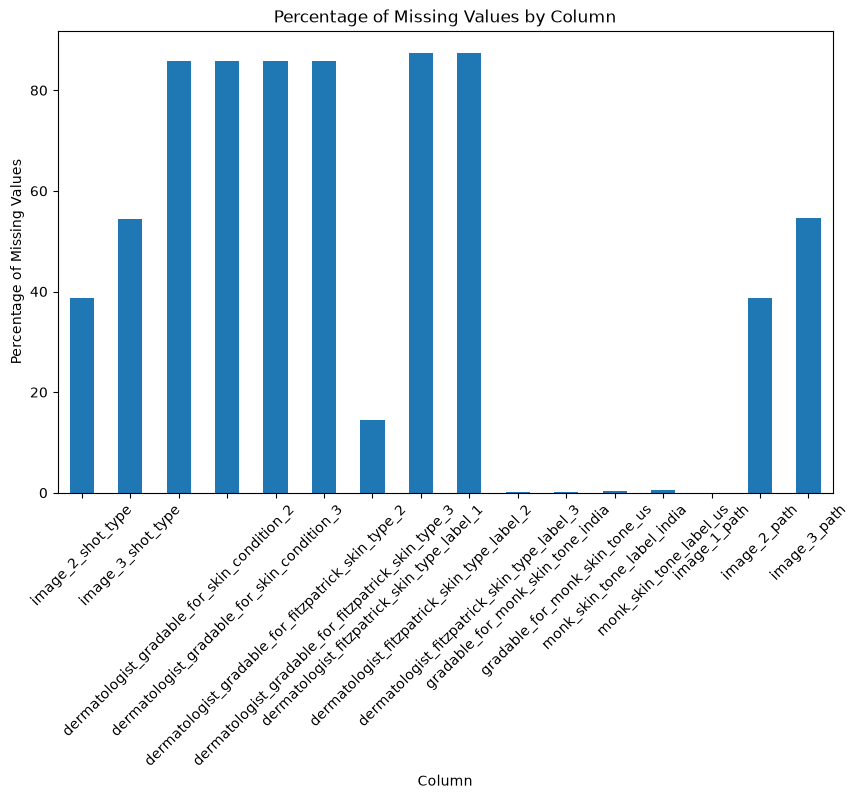

In [14]:
plt.figure(figsize=(10, 6))
missing_pct.plot(kind='bar')
plt.title('Percentage of Missing Values by Column')
plt.xlabel('Column')
plt.ylabel('Percentage of Missing Values')
plt.xticks(rotation=45)
plt.show()

### Quasi-constant Columns

In [15]:
#Indenfiying quasi-constant columns
threshold = 0.99
quasi_constant_cols = [
    col for col in df.columns
    if (df[col].value_counts(normalize=True, dropna=False).max() >= threshold)]
quasi_constant_cols

['source',
 'release',
 'year',
 'race_ethnicity_middle_eastern_or_north_african',
 'race_ethnicity_native_hawaiian_or_pacific_islander',
 'race_ethnicity_other_race',
 'race_ethnicity_prefer_not_to_answer',
 'gradable_for_monk_skin_tone_india',
 'gradable_for_monk_skin_tone_us']

In [16]:
cols = ["gradable_for_monk_skin_tone_india", "gradable_for_monk_skin_tone_us"]
display(df[cols].apply(lambda col: col.value_counts(dropna=False)))

print(df[cols].isna().sum())
print(df[cols].notna().sum())

,gradable_for_monk_skin_tone_india,gradable_for_monk_skin_tone_us
0.0,4.0,18.0
1.0,5019.0,5005.0
NaN,NaN,NaN
NaN,NaN,NaN


gradable_for_monk_skin_tone_india    10
gradable_for_monk_skin_tone_us       10
dtype: int64
gradable_for_monk_skin_tone_india    5023
gradable_for_monk_skin_tone_us       5023
dtype: int64


In [17]:
quasi_constant_Table = pd.DataFrame({
    'Column Name': quasi_constant_cols,
    'Unique Values': [df[col].value_counts().to_dict() for col in quasi_constant_cols]
})
display(quasi_constant_Table)

,Column Name,Unique Values
0,source,{'SCIN': 5033}
1,release,{'1.0.0': 5033}
2,year,{2023: 5033}
3,race_ethnicity_middle_eastern_or_north_african,"{0: 5026, 1: 7}"
4,race_ethnicity_native_hawaiian_or_pacific_isla...,"{0: 5029, 1: 4}"
5,race_ethnicity_other_race,"{0: 5017, 1: 16}"
6,race_ethnicity_prefer_not_to_answer,"{0: 4999, 1: 34}"
7,gradable_for_monk_skin_tone_india,"{1: 5019, 0: 4}"
8,gradable_for_monk_skin_tone_us,"{1: 5005, 0: 18}"


#### Dropping quasi-constant columns

In [18]:
df.drop(
    columns=["source", "release", "year", "gradable_for_monk_skin_tone_india", "gradable_for_monk_skin_tone_us"],
    inplace=True
)

## X, y, train, test, validate splitting

In [19]:
#Target
y = df["weighted_skin_condition_label"].copy()
y = y.apply(lambda x: literal_eval(x) if isinstance(x, str) and x != "{}" else {})
y

0       {'Inflicted skin lesions': 0.41, 'Eczema': 0.4...
1       {'Prurigo nodularis': 0.41, 'SCC/SCCIS': 0.41,...
2       {'Impetigo': 0.55, 'Herpes Zoster': 0.23, 'Bul...
3                                                      {}
4       {'Lichen planus/lichenoid eruption': 0.33, 'Fo...
                              ...                        
5028    {'CD - Contact dermatitis': 0.33, 'Allergic Co...
5029                                                   {}
5030               {'Impetigo': 0.5, 'Foreign body': 0.5}
5031    {'Erythema gyratum repens': 0.33, 'Seborrheic ...
5032                                {'Folliculitis': 1.0}
Name: weighted_skin_condition_label, Length: 5033, dtype: object

In [20]:
X_images = df[["case_id"] + image_cols].copy()
# Clinical metadata
clinical_prefixes = (
    "textures_",
    "body_parts_",
    "condition_symptoms_",
    "other_symptoms_"
)

binary_features = df.columns[
    df.columns.str.startswith(clinical_prefixes)
].tolist()

categorical_features = [
    "age_group",
    "sex_at_birth",
    "fitzpatrick_skin_type",
    "related_category",
    "condition_duration"
]

X_metadata = df[binary_features + categorical_features].copy()

In [21]:
valid_idx = y.apply(len) > 0

X_metadata = X_metadata[valid_idx]
X_images = X_images[valid_idx]
y = y[valid_idx]

In [22]:
display(X_metadata.shape)
display(X_images.shape)
display(y.shape)

(3061, 36)

(3061, 4)

(3061,)

In [23]:
y.head(50)

0     {'Inflicted skin lesions': 0.41, 'Eczema': 0.4...
1     {'Prurigo nodularis': 0.41, 'SCC/SCCIS': 0.41,...
2     {'Impetigo': 0.55, 'Herpes Zoster': 0.23, 'Bul...
4     {'Lichen planus/lichenoid eruption': 0.33, 'Fo...
5     {'Drug Rash': 0.41, 'Viral Exanthem': 0.41, 'E...
6     {'Urticaria': 0.6, 'Leukocytoclastic Vasculiti...
7     {'Basal Cell Carcinoma': 0.55, 'Inflicted skin...
8     {'Eczema': 0.67, 'Psoriasis': 0.11, 'Acute and...
9                                      {'Purpura': 1.0}
10    {'Eczema': 0.55, 'Drug Rash': 0.23, 'Allergic ...
11                                   {'Urticaria': 1.0}
13    {'Skin infection': 0.33, 'Scabies': 0.33, 'Mol...
15    {'Tinea Versicolor': 0.46, 'Urticaria': 0.35, ...
17    {'Stasis Dermatitis': 0.33, 'Eczema': 0.33, 'A...
18    {'Tinea Versicolor': 0.61, 'Seborrheic Dermati...
19    {'Lichen planus/lichenoid eruption': 0.33, 'In...
21             {'Urticaria': 0.67, 'Insect Bite': 0.33}
22    {'Lichen planus/lichenoid eruption': 0.5, 

In [24]:
diagnosis_counts = Counter()

for labels in y.dropna():
    if isinstance(labels, dict):
        diagnosis_counts.update(labels.keys())

diagnosis_counts = (
    pd.Series(diagnosis_counts)
    .sort_values(ascending=False)
)

display(diagnosis_counts)

print("Total diagnoses:", len(diagnosis_counts))

Eczema                                                           1056
Allergic Contact Dermatitis                                       873
Insect Bite                                                       403
Urticaria                                                         332
Psoriasis                                                         308
                                                                 ... 
Abrasion and/or friction burn of lower limb without infection       1
Bullosis diabeticorum                                               1
Leprosy                                                             1
Varicose veins of lower extremity                                   1
Erythema marginatum in acute rheumatic fever                        1
Length: 370, dtype: int64

Total diagnoses: 370


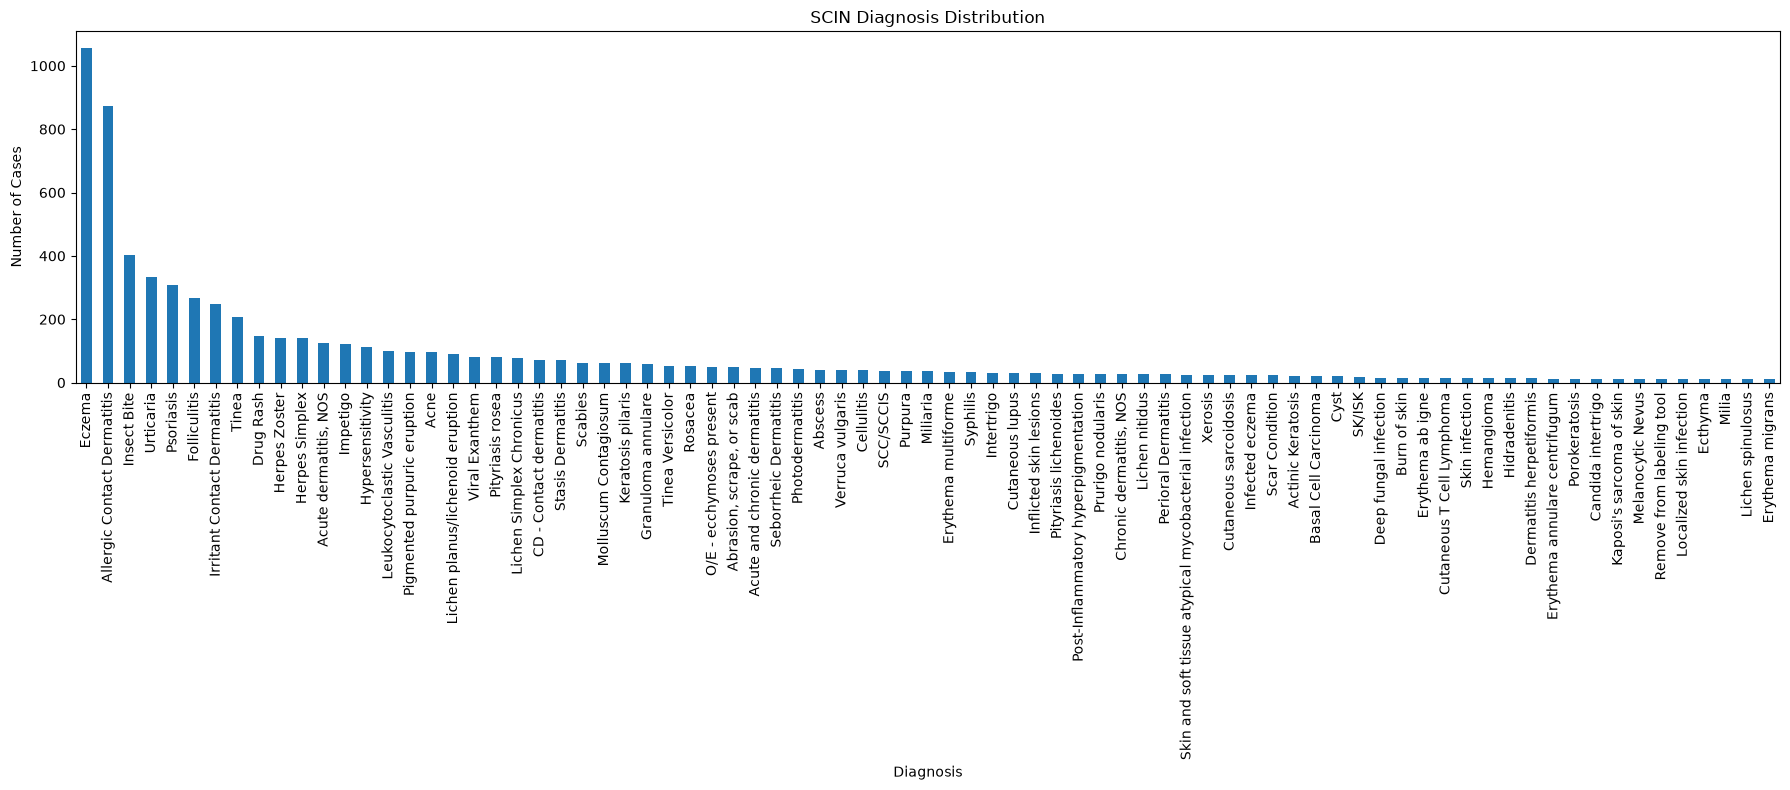

In [25]:
plt.figure(figsize=(18, 8))

diagnosis_counts[lambda x:x>10].plot(kind="bar")

plt.title("SCIN Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [26]:
#Checking support for common skin conditions in Palestine
keywords = [
    "vitil",
    "melasma",
    "hidr",
    "alopecia",
    "onych",
    "wart",
    "verruca",
    "nevus",
    "mole",
    "leish"
]

for k in keywords:
    print("\n", k)
    print(
        diagnosis_counts[
            diagnosis_counts.index.str.contains(
                k,
                case=False,
                na=False
            )
        ]
    )


 vitil
Vitiligo    6
dtype: int64

 melasma
Melasma    5
dtype: int64

 hidr
Hidradenitis                                    14
Acute-on-chronic dyshidrotic eczema of hands     1
dtype: int64

 alopecia
Frontal fibrosing alopecia    1
Traction alopecia             1
dtype: int64

 onych
Onychomycosis             7
Paronychia                5
Onychodystrophy           2
Pachyonychia congenita    1
Leukonychia               1
dtype: int64

 wart
Series([], dtype: int64)

 verruca
Verruca vulgaris    40
dtype: int64

 nevus
Melanocytic Nevus         12
Atypical Nevus             5
Epidermal nevus            5
Nevus anemicus             1
Vascular nevus of skin     1
dtype: int64

 mole
Series([], dtype: int64)

 leish
Cutaneous leishmaniasis    3
dtype: int64


### Encoding Labels

In [27]:
target_classes = diagnosis_counts[diagnosis_counts >= 50].index.tolist()
common_candidates =["Seborrheic Dermatitis",
                    "Cellulitis",
                    "Abscess",
                    "SCC/SCCIS",
                    "Basal Cell Carcinoma",
                    "Melanoma",
                    "Cutaneous lupus",
                    "Syphilis",
                    "Verruca vulgaris",
                    "Onychomycosis",
                    "Hidradenitis",
                    "Melanocytic Nevus",
                    "Vitiligo",
                    "Melasma",
                    "Cutaneous leishmaniasis"]
target_classes.extend([c for c in common_candidates
                       if c in diagnosis_counts.index
                       and diagnosis_counts[c] >= 10])
target_classes.append("Other")

def encode_labels(label_dict):
    y = np.zeros(len(target_classes))

    other = 0

    for disease, confidence in label_dict.items():
        if disease in target_classes:
            y[target_classes.index(disease)] = confidence
        else:
            other += confidence

    y[target_classes.index("Other")] = other

    return y / y.sum()

In [28]:
Y = np.stack(
    y.apply(encode_labels))

Y.shape

(3061, 41)

In [29]:
label_counts = pd.Series(
    (Y > 0).sum(axis=0),
    index=target_classes
).sort_values(ascending=False)

display(label_counts)

Other                               1115
Eczema                              1056
Allergic Contact Dermatitis          873
Insect Bite                          403
Urticaria                            332
Psoriasis                            308
Folliculitis                         268
Irritant Contact Dermatitis          249
Tinea                                206
Drug Rash                            148
Herpes Zoster                        142
Herpes Simplex                       141
Acute dermatitis, NOS                124
Impetigo                             121
Hypersensitivity                     113
Leukocytoclastic Vasculitis           99
Pigmented purpuric eruption           98
Acne                                  98
Lichen planus/lichenoid eruption      89
Viral Exanthem                        82
Pityriasis rosea                      80
Lichen Simplex Chronicus              78
Stasis Dermatitis                     70
CD - Contact dermatitis               70
Molluscum Contag

In [30]:
other_idx = target_classes.index("Other")

print(
    "Only Other:",
    ((Y[:, other_idx] == 1) & (Y.sum(axis=1) == 1)).sum()
)

Only Other: 220
